In [2]:
import os
from dataclasses import asdict

import numpy as np
import pandas as pd
import torch

from paths import ROOT_PROJECT_PATH
from data.utils_io import load_config, load_json, load_best_checkpoint
from data.dataset import (
    GraphSignalDataset,
    create_splits_from_indices
)
from baselines.sparse_VGAE.gae import GAE
from graph_wavelet_transform.forward import gwt
from graph_wavelet_transform.utils import reshape_coeffs_to_2d
from baselines.sparse_VGAE.reconstruction_utils import monte_carlo_averaging_reconstruction
from visualization.training_loss import plot_train_val_losses
from visualization.gwt_coeffs import visualize_grid_graph_sgwt_coefficients, visualize_grid_graph_inverse_sgwt_reconstruction, visualize_energy_distribution_across_scales
from models.sparsification import SingleSampleDirectOptimization

In [55]:
local_storage_dir = os.path.join(ROOT_PROJECT_PATH, "local_storage")
# GAE - ste_fixed - 0.01
# run_dir = os.path.join(local_storage_dir, 'runs', '2025-11-24_10-35-58')

# GAE - ste_fixed - 0.05
# run_dir = os.path.join(local_storage_dir, 'runs', '2025-11-25_15-17-34')

# GAE - ste_fixed - 0.1
run_dir = os.path.join(local_storage_dir, 'runs', '2025-11-25_16-12-17')

# GAE - ste_annealing
# run_dir = os.path.join(local_storage_dir, 'runs', '2025-11-23_21-18-57')

# GAE - gumbel
# run_dir = os.path.join(local_storage_dir, 'runs', '2025-11-23_22-25-38')

# VGAE - gumbel - kl 0.01
# run_dir = os.path.join(local_storage_dir, 'runs', '2025-11-23_23-09-22')

# VGAE - gumbel - kl 0.0001
# run_dir = os.path.join(local_storage_dir, 'runs', '2025-11-23_23-52-31')

# loading the training configs
configs = load_config(config_dir=run_dir,
                     config_name='sparse_gae_pretraining_config.json')
base_data_dir = configs.base_data_dir
print(f"Configs for keep_ratio: {configs.keep_ratio} ")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

Configs for keep_ratio: 0.001953125 


In [56]:
asdict(configs)

{'base_data_dir': '/Users/amirhossein/Projects/NJIT/graph_wavelet_compressed_sensing/local_storage/data/2025-10-25_11-45-48',
 'random_seed': 13,
 'train_ratio': 0.6,
 'val_ratio': 0.2,
 'test_ratio': 0.2,
 'batch_size': 16,
 'keep_ratio': 0.001953125,
 'sparsity_initial_value': 1.0,
 'sparsity_final_value': 0.1,
 'sparsity_scheduler_final_epoch': 0,
 'sparsity_scheduler_strategy': 'cosine',
 'lr_scheduler_factor': 0.5,
 'lr_scheduler_patience': 50,
 'lr_scheduler_min_lr': 1e-06,
 'early_stopping_patience': 300,
 'early_stopping_patience_min_delta': 0.0001,
 'model_name': 'GAE',
 'processor_num_layers': 5,
 'output_dim': 1,
 'latent_dim': 256,
 'activation_function': 'relu',
 'conv_layer_type': 'SAGEConv',
 'lr': 0.001,
 'weight_decay': 0.0005,
 'epochs': 5000,
 'variational': False,
 'sparsity_mask_mode': 'ste_fixed',
 'beta_kl': 0.0001}

In [57]:
split_indices = load_json(filename='split_indices.json', save_dir=run_dir)
dataset = GraphSignalDataset(base_data_dir=base_data_dir)
train_dataset, val_dataset, test_dataset = create_splits_from_indices(dataset=dataset,
                                                                      train_indices=split_indices['train'],
                                                                      val_indices=split_indices['val'],
                                                                      test_indices=split_indices['test'])

In [58]:
last_checkpoint = load_best_checkpoint(checkpoints_dir=os.path.join(run_dir, 'checkpoints'))
last_checkpoint.keys()

dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'train_loss', 'val_loss'])

In [59]:
# Initialize model
model = GAE(
    input_dim=dataset[0].x.size(1),
    latent_dim=configs.latent_dim,
    output_dim=configs.output_dim,
    num_encoder_layers=configs.processor_num_layers,
    num_decoder_layers=configs.processor_num_layers,
    conv_layer_type=configs.conv_layer_type,
    activation_function=configs.activation_function,
    sparsity_ratio=configs.keep_ratio,
    variational=configs.variational,
    sparsity_mode=configs.sparsity_mask_mode
)
model.to(device)
model.load_state_dict(last_checkpoint['model_state_dict'])
model.eval()
print(f"Best model loaded (Epoch: {last_checkpoint['epoch']}, Train Loss: {last_checkpoint['train_loss']:.6f}, Val Loss: {last_checkpoint['val_loss']:.6f})")

Best model loaded (Epoch: 232, Train Loss: 0.031726, Val Loss: 0.028852)


In [60]:
model

GAE(
  (encoder): GNNEncoder(
    (conv_layers): ModuleList(
      (0): SAGEConv(1, 256, aggr=mean)
      (1-4): 4 x SAGEConv(256, 256, aggr=mean)
    )
    (layer_norms): ModuleList(
      (0): LayerNorm((1,), eps=1e-05, elementwise_affine=True)
      (1-3): 3 x LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    )
  )
  (decoder): GNNDecoder(
    (conv_layers): ModuleList(
      (0-3): 4 x SAGEConv(256, 256, aggr=mean)
      (4): SAGEConv(256, 1, aggr=mean)
    )
    (layer_norms): ModuleList(
      (0-3): 4 x LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    )
  )
  (sparsity_mask): SparsityMask()
)

In [61]:
train_loss = load_json(filename='train_loss.json',
                       save_dir=run_dir)
val_loss = load_json(filename='val_loss.json',
                     save_dir=run_dir)

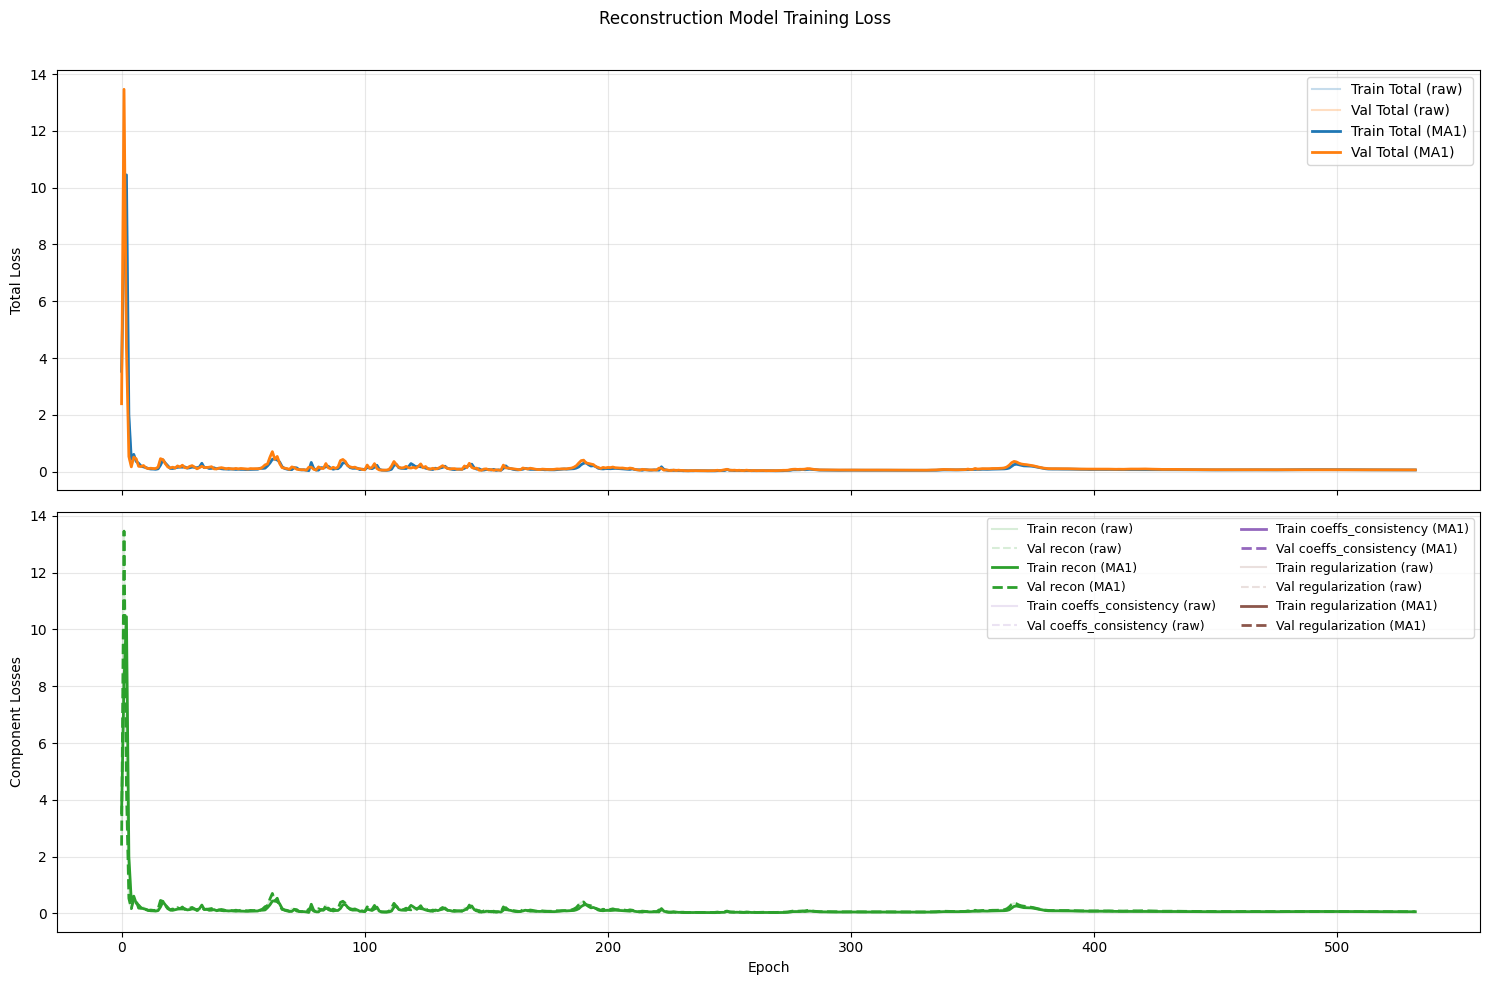

In [62]:
plot_train_val_losses(train_losses_history=train_loss,
                      val_losses_history=val_loss,
                      window_size=1,
                      figsize=(15, 10),
                      suptitle='Reconstruction Model Training Loss')

Sample 1/20
shape: torch.Size([600, 1])
SparseGAE reconstruction VS input signal:


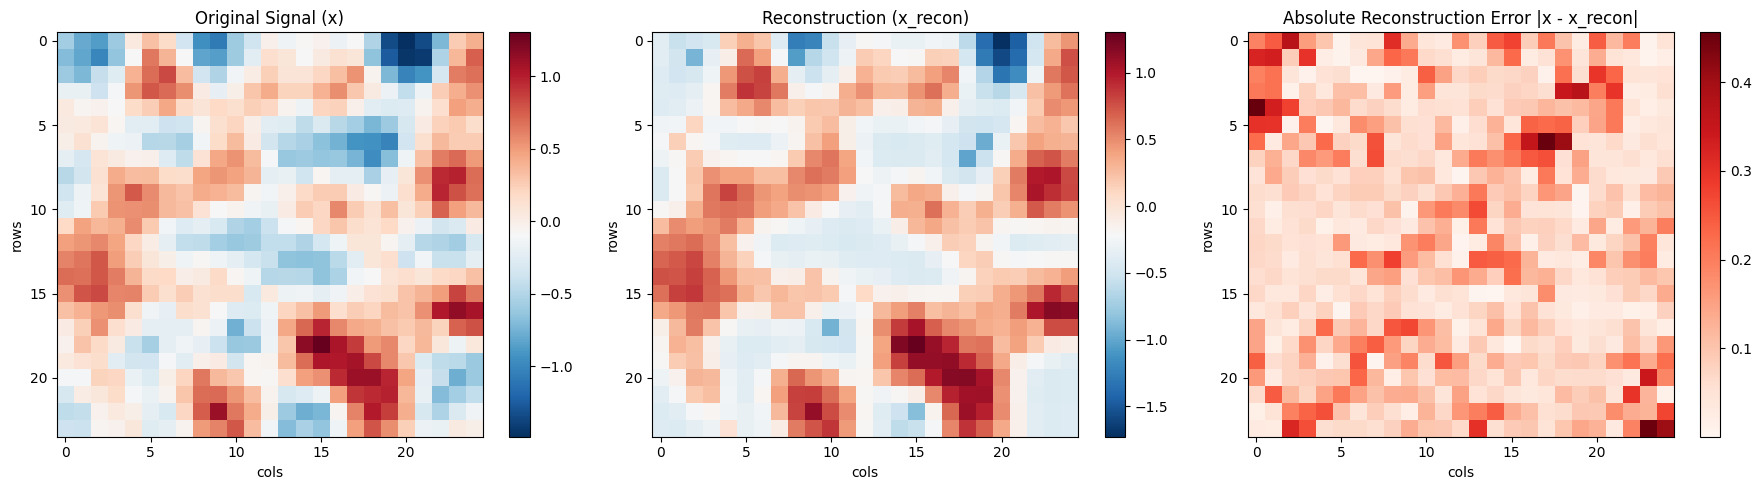

Max absolute error: 0.456253
Mean squared error: 0.017010
RMSE: 0.130424
SparseGAE reconstruction VS clean signal:


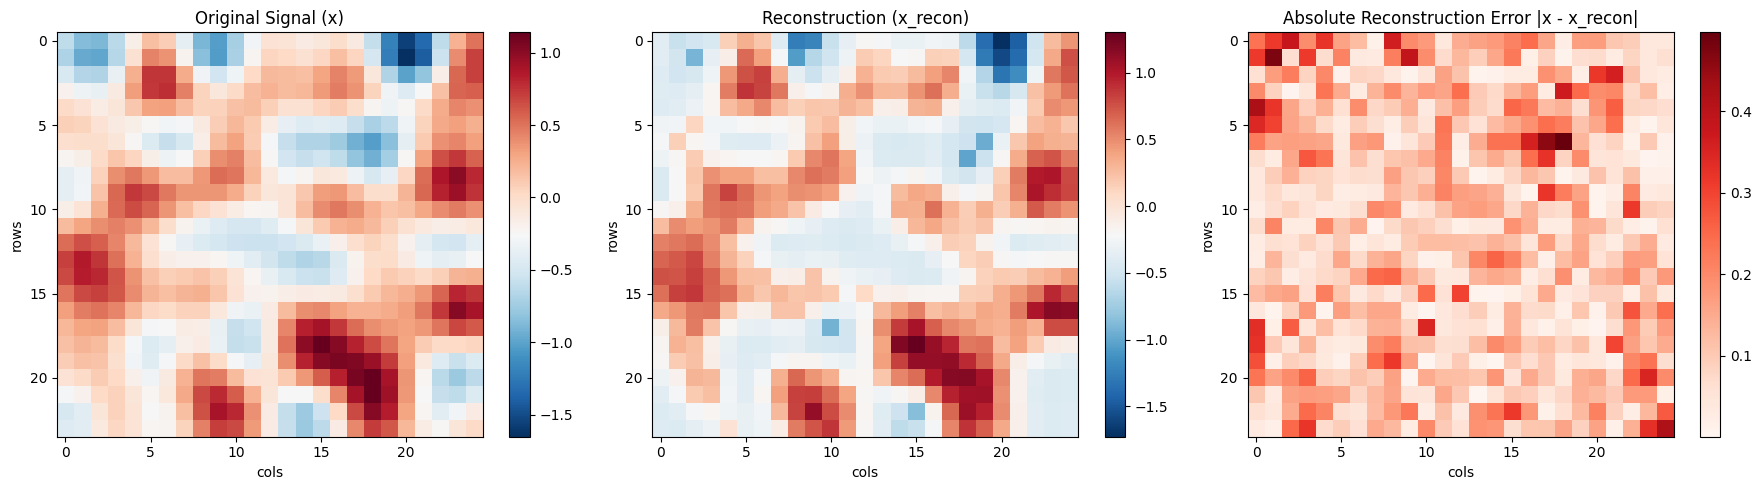

Max absolute error: 0.497214
Mean squared error: 0.021259
RMSE: 0.145805
Sample 17/20
shape: torch.Size([168, 1])
SparseGAE reconstruction VS input signal:


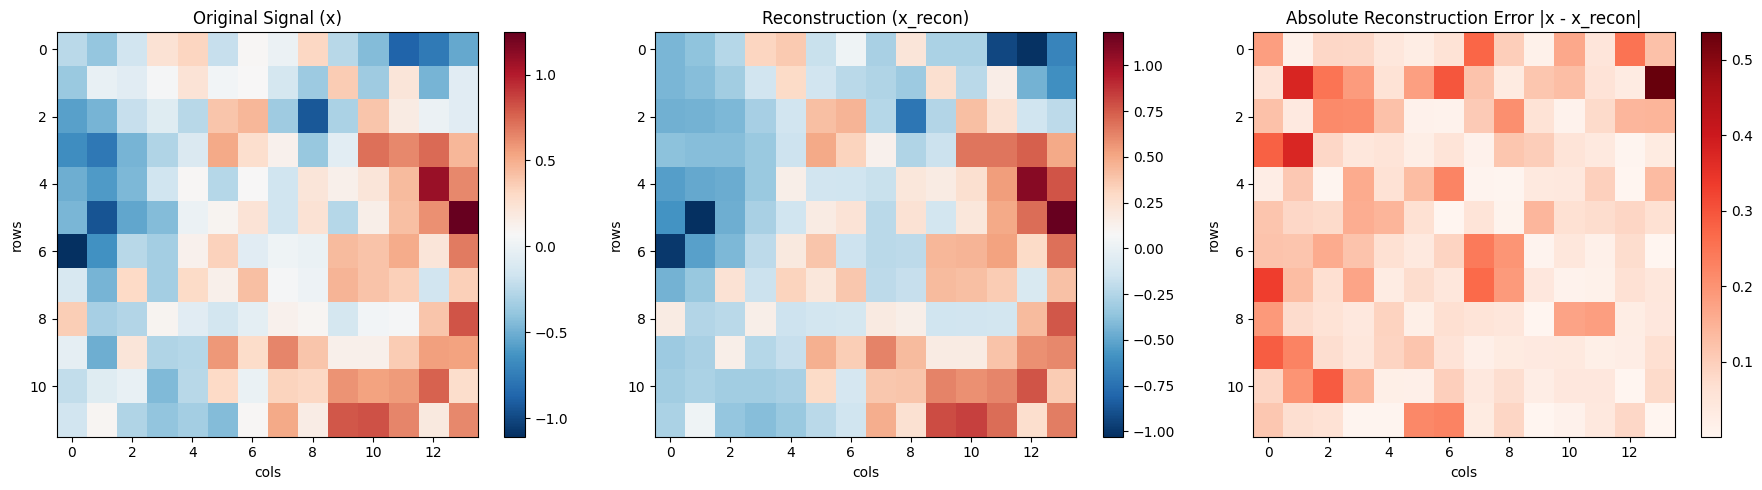

Max absolute error: 0.536256
Mean squared error: 0.016651
RMSE: 0.129039
SparseGAE reconstruction VS clean signal:


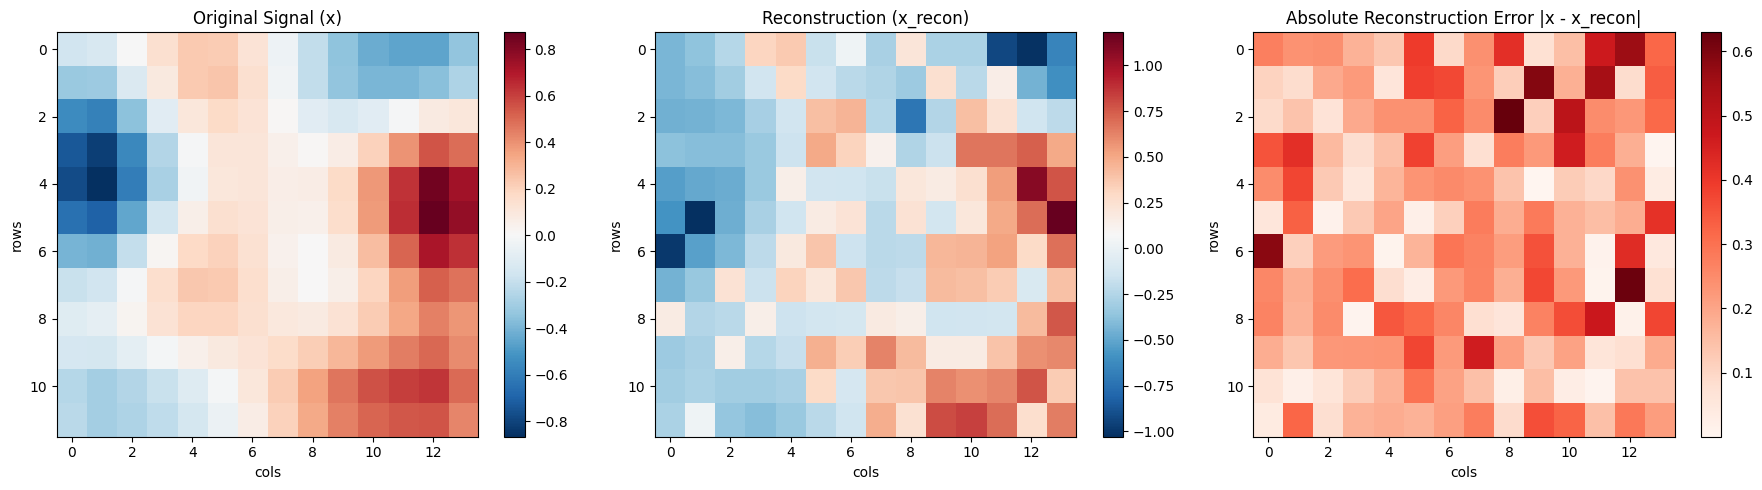

Max absolute error: 0.629430
Mean squared error: 0.063898
RMSE: 0.252781


In [63]:
keep_ratio = configs.keep_ratio
target_dataset = test_dataset
num_samples = len(target_dataset)
reconstruction_mode = "monte_carlo_averaging"  # "monte_carlo_averaging" or "single_mask"
errors = {
    "single_mask": {
        "model": [],
        "model_clean": [],
    },
    "monte_carlo_averaging": {
        "model": [],
        "model_clean": [],
    }
}
for i in range(num_samples):
    if i + 1 not in [1, 17]:
        continue
    # print("=" * 80)
    print(f"Sample {i+1}/{num_samples}")
    # print("=" * 80)
    data = target_dataset[i]

    num_nodes = data['graph_metadata']['num_nodes']
    rows=data['graph_metadata']['height']
    cols=data['graph_metadata']['width']
    x_clean = torch.tensor(data['signal_metadata']['x_clean'], dtype=torch.float32)
    for reconstruction_mode in ["monte_carlo_averaging", "single_mask"]:
        if reconstruction_mode == "monte_carlo_averaging":
            k = 1
        else:
            k = 1
        # model reconstruction
        x_hat = monte_carlo_averaging_reconstruction(data=data,
                                                     model=model,
                                                     k=k)
        # compute errors
        error_model = data.x.squeeze() - x_hat.squeeze()
        error_model_clean = x_clean.squeeze() - x_hat.squeeze()

        errors[reconstruction_mode]["model"].append({
            "mean_abs": error_model.abs().mean().item(),
            "mean_sq": (error_model ** 2).mean().item()
        })
        errors[reconstruction_mode]["model_clean"].append({
            "mean_abs": error_model_clean.abs().mean().item(),
            "mean_sq": (error_model_clean ** 2).mean().item()
        })

        if reconstruction_mode == "monte_carlo_averaging":
            print(f"shape: {x_hat.shape}")
            print("SparseGAE reconstruction VS input signal:")
            visualize_grid_graph_inverse_sgwt_reconstruction(x_recon=x_hat,
                                                             x=data.x,
                                                             rows=rows,
                                                             cols=cols,
                                                             save_fig=False)
            print("SparseGAE reconstruction VS clean signal:")
            visualize_grid_graph_inverse_sgwt_reconstruction(x_recon=x_hat,
                                                             x=x_clean,
                                                             rows=rows,
                                                             cols=cols,
                                                             save_fig=False)
    # break


In [32]:

import numpy as np

# Aggregate errors for both modes
for mode in ["single_mask", "monte_carlo_averaging"]:
    print(f"\n{mode.replace('_', ' ').title()}:")
    print("-" * 50)

    # MSE for model (noisy input)
    mse_model = [e["mean_sq"] for e in errors[mode]["model"]]
    mse_model_mean = np.mean(mse_model)
    mse_model_std = np.std(mse_model)
    print(f"MSE x:       {mse_model_mean:.3f} ± {mse_model_std:.3f}")

    # MSE for model_clean
    mse_clean = [e["mean_sq"] for e in errors[mode]["model_clean"]]
    mse_clean_mean = np.mean(mse_clean)
    mse_clean_std = np.std(mse_clean)
    print(f"MSE x_clean: {mse_clean_mean:.3f} ± {mse_clean_std:.3f}")


Single Mask:
--------------------------------------------------
MSE x:       0.027 ± 0.020
MSE x_clean: 0.049 ± 0.025

Monte Carlo Averaging:
--------------------------------------------------
MSE x:       0.027 ± 0.020
MSE x_clean: 0.049 ± 0.025
